In [72]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact 

<script type="text/x-mathjax-config">
  MathJax.Hub.Config({
    TeX: { equationNumbers: { autoNumber: "all" } }
  });
</script>


In [73]:
# Hàm tín hiệu liên tục (sin)
def continuous_signal(t):
    return np.sin(2 * np.pi * 5 * t)  # Tín hiệu sin với tần số 5Hz

In [74]:
def continuous_signal(t):
    return np.cos(2 * np.pi * 5 * t)  # Tín hiệu cos với tần số 5Hz

In [75]:
def continuous_signal(t):
    return signal.square(2 * np.pi * 5 * t)  # Tín hiệu sóng vuông với tần số 5Hz

In [76]:
def continuous_signal(t):
    return signal.sawtooth(2 * np.pi * 5 * t)  # Tín hiệu sóng răng cưa với tần số 5Hz

In [77]:
def continuous_signal(t):
    return signal.sawtooth(2 * np.pi * 5 * t)  # Tín hiệu sóng răng cưa với tần số 5Hz

In [78]:
def continuous_signal(t):
    return np.exp(-t) * np.sin(2 * np.pi * 5 * t)  # Tín hiệu hàm mũ giảm dần

In [79]:
def continuous_signal(t):
    return np.random.normal(0, 1, len(t))  # Tín hiệu ngẫu nhiên phân phối chuẩn

* Phát triển hàm cho phép phát các tín hiệu tương tự khác nhau



In [80]:
def gen_continous_signal(t, time_shift=0.0, freq=1.0, amplitude=1.0, signal_type='sinusoidal'):
    switcher = {
        'sinusoidal': lambda: amplitude * np.sin(2 * np.pi * freq * (t - time_shift)),
        'sawtooth': lambda: amplitude * signal.sawtooth(2 * np.pi * freq * (t - time_shift)),
        'square': lambda: amplitude * signal.square(2 * np.pi * freq * (t - time_shift)),
        'gauss_pulse': lambda: amplitude * signal.gausspulse(t-time_shift, fc=freq)
    }
    # Gọi hàm lambda để lấy kết quả
    return switcher.get(signal_type, lambda: amplitude * np.sin(2 * np.pi * freq * (t - time_shift)))()

#### 1. Quá trình lấy mẫu

In [81]:
# 1. Lấy mẫu (Sampling)
def sampling(continuous_signal, sampling_rate, duration):
    t = np.linspace(0, duration, int(sampling_rate * duration), endpoint=False)
    return t, continuous_signal(t)

#### 2. Quá trình lượng tử hóa

##### 2.1. Chuẩn hóa tín hiệu theo các phương pháp khác nhau

<script type="text/x-mathjax-config">
  MathJax.Hub.Config({
    TeX: { equationNumbers: { autoNumber: "all" } }
  });
</script>

1. Chuẩn hóa Min-Max (Min-Max Normalization)


\begin{equation}
    x^{'}=\frac{x−\min\left(x\right)​}{\max\left(x\right)−\min\left(x\right)}
\end{equation}

In [82]:
def min_max_norm(x):
    return np.float32(x - np.min(x))/(np.max(x)-np.min(x))

2. Chuẩn hóa Z-score (Standardization)

\begin{equation}
\tag{2}
    x^{'} = \frac{x - \mu}{\sigma}
\end{equation}

In [83]:
def z_score_norm(x, mean = 0, deviation = 1):
    return (x - mean)/deviation

3. Chuẩn hóa RMS (Root Mean Square Normalization)

\begin{equation}
\tag{3}
x^{'} = \frac{x}{x_{\text{RMS}}}
\end{equation}

Trong đó: 

\begin{equation}
\tag{4}
x_{\text{RMS}}= \sqrt{\frac{1}{N} \sum_{i=1}^{N} x_i^2}
\end{equation}


In [84]:
def rms_norm(x):
    rms = np.sqrt(np.sum(x**2))/ len(x)
    return x / rms

4. Chuẩn hóa theo giá trị tuyệt đối tối đa (Max Abs Scaling)

\begin{equation}
\tag{5}
x^{'} = \frac{x}{\max\left(\left|x\right|\right)}
\end{equation}

In [85]:
def max_abs_norm(x):
    return x/ np.max(np.abs(x))

* Lựa chọn các phương pháp chuẩn hóa

In [86]:
def normalizing_signal(signal, normalized_type = 'min_max'):
    switcher = {
        'min_max': lambda: min_max_norm(signal),
        'z_score': lambda: z_score_norm(signal),
        'rms': lambda: rms_norm(signal),
        'max_abs': lambda: max_abs_norm(signal)
    }

    return switcher.get(normalized_type, lambda: min_max_norm(signal))()

##### 2.2 Quá trình lượng tử hóa


1. Tự tính toán giá trị lượng tử

\begin{equation}
\tag{6}
x_{\text{quantized}} = \frac{\left\lfloor {x_{\text{normalized}}} \times {\left(L-1\right)  } \right\rceil}{\left({L-1}\right)}
\end{equation}

* Hàm lượng tự hóa tự phát triển: quantization()

In [87]:
# 2. Lượng tử hóa (Quantization)
def quantization(signal, levels, min_range=0.0, max_range=1.0, normalized_type = 'min_max'):
    sig_list = []
    
    if not (normalized_type == None):
        normalized_signal = normalizing_signal(signal, normalized_type)
        clipped_signal = np.clip(normalized_signal, min_range, max_range)
    else:
        clipped_signal = signal
        normalized_signal =signal
    
    quantized_signal = np.round(clipped_signal * np.float32(levels-1)) / np.float32(levels-1)
    return quantized_signal

* Lượng tử hóa sử dụng thư viện numpy

numpy.digitize(x, bins, right=False)

right = False: chọn bin bên trái nếu gặp giá trị x đúng vị trí bin
right = True: chọn bin bên phải

In [88]:
def quantization_np(signal, levels, min_range=0, max_range=1, normalized_type = 'min_max'):
    normalized_signal = normalizing_signal(signal, normalized_type)
    bins = np.linspace(min_range, max_range, num=levels)
    quantized_signal = np.digitize(normalized_signal, bins, right=False)
    return quantized_signal, min_range, max_range

* Kiểm thử quá trình lượng tử hóa

signal = contineous_signal 

#### 3. Quá trình mã hóa

In [89]:
# 3. Mã hóa (Encoding)
def encoding(quantized_signal, levels):
    bits_per_sample = int(np.ceil(np.log2(levels)))
    
    encoded_signal = [
        format(int(round(val * (levels - 1))), f'0{bits_per_sample}b')
        for val in quantized_signal
    ]
    
    return encoded_signal

#### 4. Kiểm thử chương trình

In [90]:
def test_quantization(sampling_rate=50, duration = 1, quantization_levels = 16):
    # Bước 1: Lấy mẫu tín hiệu liên tục
    t, sampled_signal = sampling(continuous_signal, sampling_rate, duration)
    
    # Bước 2: Lượng tử hóa tín hiệu 
    quantized_signal = quantization(sampled_signal, quantization_levels)

    print('sampled_signal = ', sampled_signal)

    print('quantized_signal by developed function: ', quantized_signal)

test_quantization()

sampled_signal =  [ 0.06067877 -1.1046384   0.58253085 -0.0934883  -1.85128217  0.21108662
 -1.43368167 -0.32758214 -0.88322284 -0.70073661 -1.43340891  0.28867062
  0.34732631 -0.1933111   0.40472892  0.55589359  0.50009596  0.24561444
  0.39188535  0.05217964 -1.76137793 -0.31337325 -0.48066267 -1.69467084
  0.48261506 -0.16031723  0.53186278 -0.59811818 -1.48514541 -0.17587186
 -0.37168029  0.87271476 -0.09800003  0.40162419  0.95881832  1.87530892
  0.41795938 -0.12030986  0.52938429  1.28626473  1.66727696  1.11882251
  1.40208539 -0.05099409 -0.84343169 -1.02458641  0.91811257 -0.64812617
  0.12809746 -0.53910942]
quantized_signal by developed function:  [0.53333333 0.2        0.66666667 0.46666667 0.         0.53333333
 0.13333333 0.4        0.26666667 0.33333333 0.13333333 0.6
 0.6        0.46666667 0.6        0.66666667 0.6        0.53333333
 0.6        0.53333333 0.         0.4        0.4        0.06666667
 0.6        0.46666667 0.66666667 0.33333333 0.06666667 0.46666667
 0.

#### 5. Biễu diễn tín hiệu

##### 5.1. Biểu diễn tín hiệu liên tục trước khi thực hiện lấy mẫu

##### Hàm showcase1

* Hàm showcase1 biểu diễn tín hiệu đơn liên tục

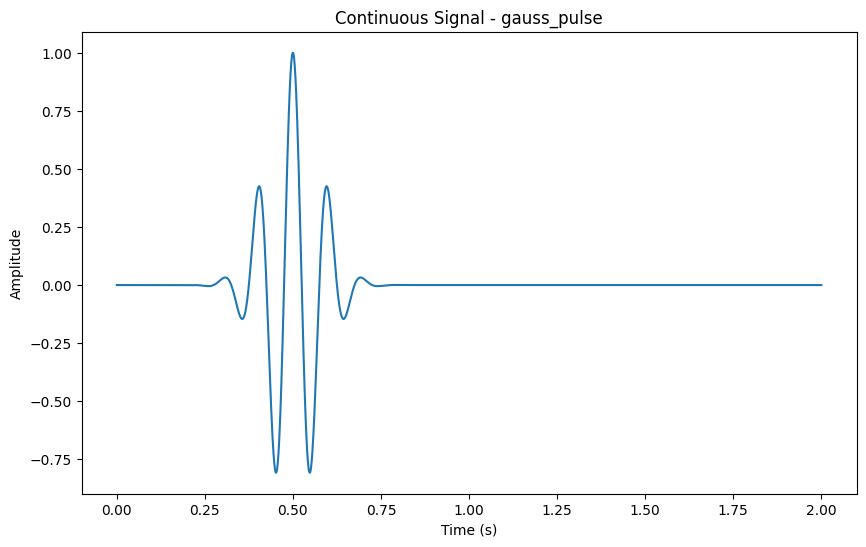

In [91]:

def showcase1(signal_type='sinusoidal', freq=5.0, duration=1.0, sampling_rate=50.0):
    t = np.linspace(0, duration, int(duration * sampling_rate))
    t_shift = 0.5
    continuous_signal = gen_continous_signal(t, freq=freq, amplitude=1, signal_type=signal_type, time_shift=t_shift)
    
    # Hiển thị tín hiệu ban đầu
    plt.figure(figsize=(10, 6))
    plt.plot(t, continuous_signal)
    plt.title(f"Continuous Signal - {signal_type}")
    plt.xlabel('Time (s)')
    plt.ylabel('Amplitude')
    plt.show()

showcase1(signal_type='gauss_pulse', freq=10.0, duration=2.0, sampling_rate=1000.0)

##### Hàm showcase1_exp 

* Hàm signal_description dùng để mô tả tín hiệu tương tự


In [92]:
def signal_description(signal_type='sinusoidal', amplitude=1.0, freq= 1.0, time_shift=0.0):
    signal = dict()
    signal['signal_type'] = signal_type
    signal['amplitude'] = amplitude
    signal['frequency'] = freq
    signal['time_shift'] = time_shift
    return signal

In [93]:
def composite_signal(signal_list, duration=1.0, sampling_rate=50.0):
    t = np.linspace(0, duration, int(duration * sampling_rate))
    tot_sig = 0
    for ind, src in enumerate(signal_list):
        sig_type = src['signal_type']
        amp = src['amplitude']
        freq = src['frequency']
        t_sh = src['time_shift']
        
        # Thêm amplitude vào hàm gen_continous_signal
        cont_sig = gen_continous_signal(t, time_shift=t_sh, freq=freq, amplitude=amp, signal_type=sig_type)
        tot_sig += cont_sig
    return tot_sig, t

* Hàm showcase1_exp để thể hiện nhiều tín hiệu cùng một lúc, cũng như tín hiệu tổng hợp. 

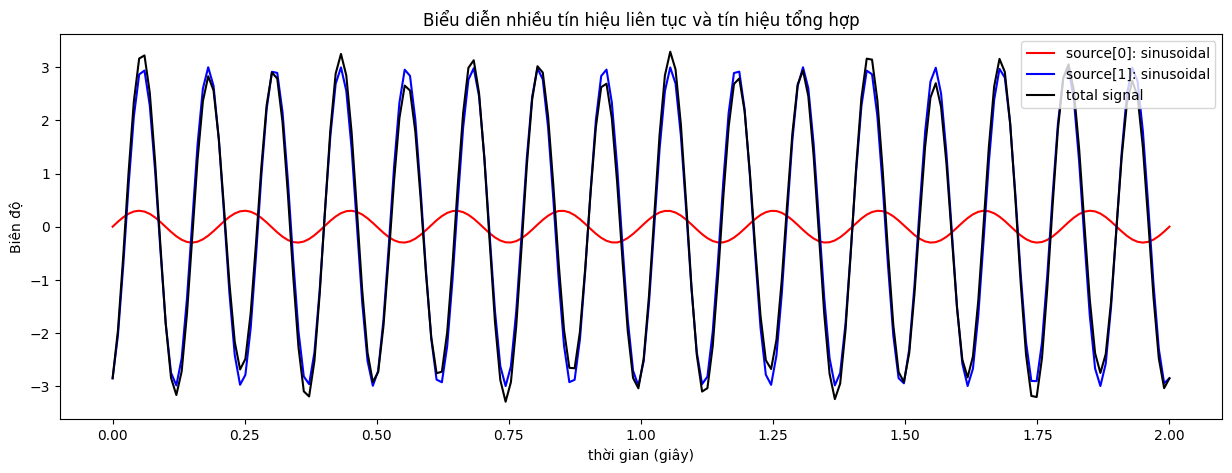

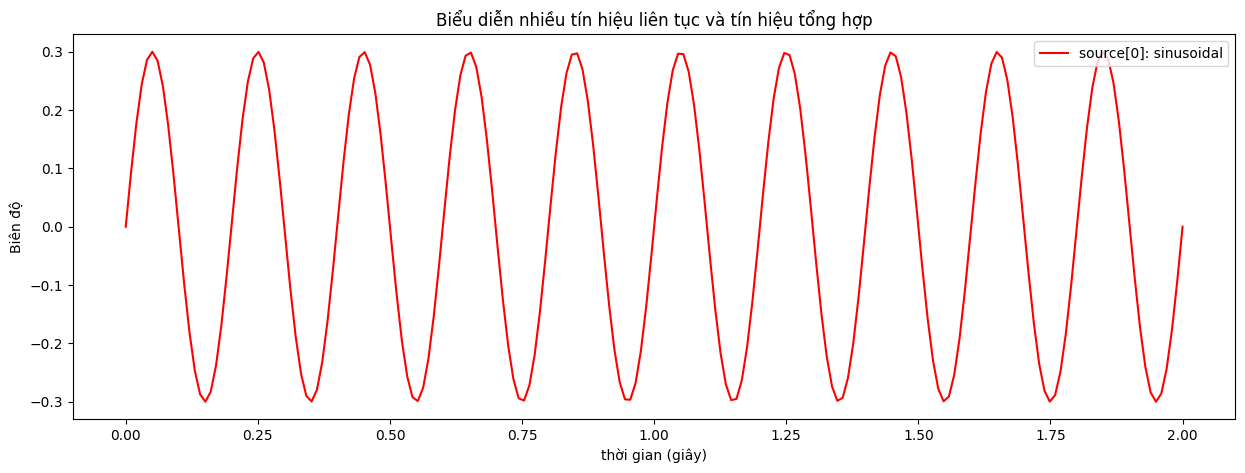

In [94]:
def showcase1_exp(signal_list, duration=1.0, sampling_rate=50.0, superposition=False, components=True):
    
    color_list = ['red', 'blue', 'green', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan']
    t = np.linspace(0, duration, int(duration * sampling_rate))

    fig, ax = plt.subplots(figsize=(15, 5))
    tot_sig = 0
    for ind, src in enumerate(signal_list):
        sig_type = src['signal_type']
        amp = src['amplitude']
        freq = src['frequency']
        t_sh = src['time_shift']
        
        # Thêm amplitude vào hàm gen_continous_signal
        cont_sig = gen_continous_signal(t, time_shift=t_sh, freq=freq, amplitude=amp, signal_type=sig_type)
        
        if components: 
            color = color_list[ind % len(color_list)]
            ax.plot(t, cont_sig, color=color, label=f'source[{ind}]: {sig_type}')
        tot_sig += cont_sig

    if superposition:
        ax.plot(t, tot_sig, color='black', label=f'total signal')

    ax.set_title('Biểu diễn nhiều tín hiệu liên tục và tín hiệu tổng hợp')
    ax.set_xlabel('thời gian (giây)')
    ax.set_ylabel('Biên độ')
    ax.legend(loc='upper right')

    plt.show()

signal_list = []

source1 = signal_description('sinusoidal', amplitude= 0.3, freq= 5, time_shift= 0)
source2 = signal_description('sinusoidal', amplitude= 3, freq= 8, time_shift= 1.9)

signal_list.append(source1)
signal_list.append(source2)

showcase1_exp(signal_list, duration=2, sampling_rate=100, superposition=True, components=True)

showcase1_exp([source1], duration=2, sampling_rate=100, superposition=False, components=True)

##### Hàm showcase2 
* Hàm showcase2 biểu diễn tín hiệu một trường hợp đơn giản về lấy mẫu, quantize và encoding
- - Chưa quan tâm đến chuẩn hóa, và các vấn đề liên quan đến chuẩn hóa
- - CHưa quan tâm đến dồn tín hiệu về chuỗi bít nhị phân. 

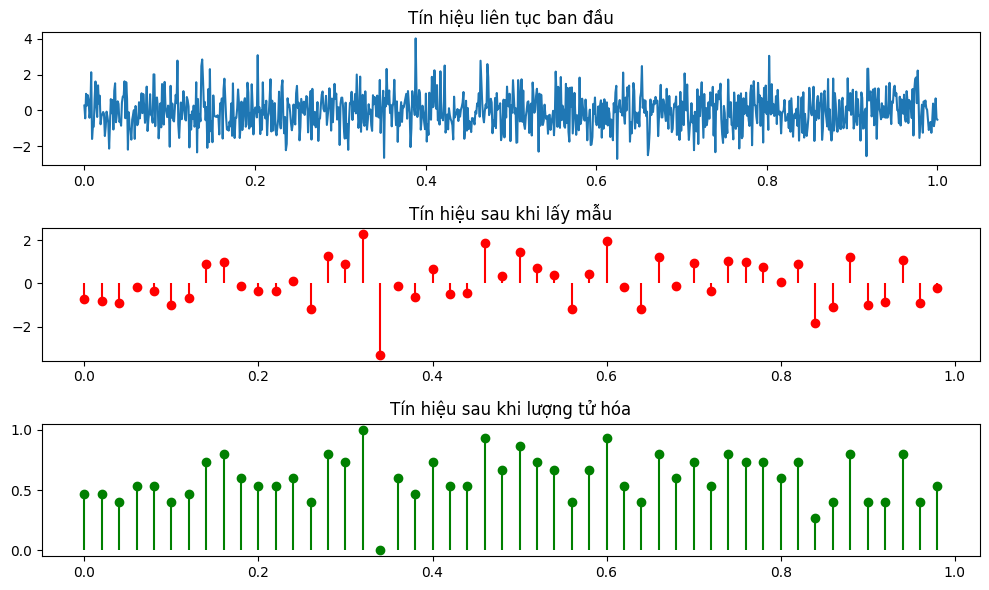

In [95]:
def showcase2(sampling_rate = 50, duration = 1, quantization_levels = 16):
    # Bước 1: Lấy mẫu tín hiệu liên tục
    t, sampled_signal = sampling(continuous_signal, sampling_rate, duration)

    # Bước 2: Lượng tử hóa tín hiệu
    quantized_signal = quantization(sampled_signal, quantization_levels)

    # Bước 3: Mã hóa tín hiệu lượng tử hóa
    encoded_signal = encoding(quantized_signal, quantization_levels)

    # Hiển thị tín hiệu ban đầu, tín hiệu lấy mẫu và lượng tử hóa
    plt.figure(figsize=(10, 6))

    plt.subplot(3, 1, 1)
    plt.plot(np.linspace(0, duration, 1000), continuous_signal(np.linspace(0, duration, 1000)))
    plt.title('Tín hiệu liên tục ban đầu')

    plt.subplot(3, 1, 2)
    plt.stem(t, sampled_signal, 'r', basefmt=" ")
    plt.title('Tín hiệu sau khi lấy mẫu')

    plt.subplot(3, 1, 3)
    plt.stem(t, quantized_signal, linefmt='g', basefmt=" ")
    plt.title('Tín hiệu sau khi lượng tử hóa')

    plt.tight_layout()
    plt.show()
    
# Các tham số
sampling_rate = 50  # Tần số lấy mẫu 50Hz
duration = 1  # Thời gian 1 giây
quantization_levels = 16  # Số mức lượng tử hóa
showcase2(sampling_rate, duration, quantization_levels)

##### 5.2 Biểu diễn tín hiệu sau khi lấy mẫu

##### 5.2.1 Hàm showcase3 
* Hàm showcase3 kiểm thử kết quả sampling 
    - Cần hàm signal_description
    - Cần hàm composite_signal


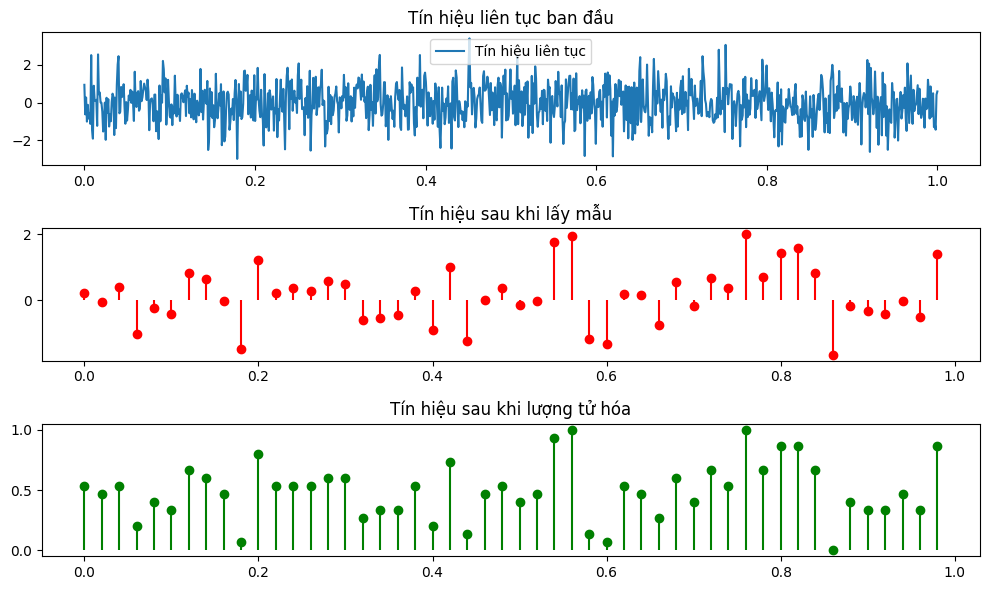

Kết quả mã hóa tín hiệu lượng tử hóa:
['1000', '0111', '1000', '0011', '0110', '0101', '1010', '1001', '0111', '0001', '1100', '1000', '1000', '1000', '1001', '1001', '0100', '0101', '0101', '1000', '0011', '1011', '0010', '0111', '1000', '0110', '0111', '1110', '1111', '0010', '0001', '1000', '0111', '0100', '1001', '0110', '1010', '1000', '1111', '1010', '1101', '1101', '1010', '0000', '0110', '0101', '0101', '0111', '0101', '1101']


In [96]:

def showcase2(sampling_rate=50, duration=1, quantization_levels=16):
    # Bước 1: Lấy mẫu tín hiệu liên tục
    t, sampled_signal = sampling(continuous_signal, sampling_rate, duration)

    # Bước 2: Lượng tử hóa tín hiệu
    quantized_signal = quantization(sampled_signal, quantization_levels)

    # Bước 3: Mã hóa tín hiệu lượng tử hóa
    encoded_signal = encoding(quantized_signal, quantization_levels)

    # Hiển thị tín hiệu ban đầu, tín hiệu lấy mẫu và lượng tử hóa
    plt.figure(figsize=(10, 6))

    plt.subplot(3, 1, 1)
    t_cont = np.linspace(0, duration, 1000)
    plt.plot(t_cont, continuous_signal(t_cont), label="Tín hiệu liên tục")
    plt.title("Tín hiệu liên tục ban đầu")
    plt.legend()

    plt.subplot(3, 1, 2)
    plt.stem(t, sampled_signal, linefmt='r', basefmt=" ")
    plt.title("Tín hiệu sau khi lấy mẫu")

    plt.subplot(3, 1, 3)
    plt.stem(t, quantized_signal, linefmt='g', basefmt=" ")
    plt.title("Tín hiệu sau khi lượng tử hóa")

    plt.tight_layout()
    plt.show()

    # In kết quả mã hóa
    print("Kết quả mã hóa tín hiệu lượng tử hóa:")
    print(encoded_signal)

# Chạy thử hàm với các tham số
sampling_rate = 50  # Tần số lấy mẫu 50Hz
duration = 1  # Thời gian 1 giây
quantization_levels = 16  # Số mức lượng tử hóa
showcase2(sampling_rate, duration, quantization_levels)

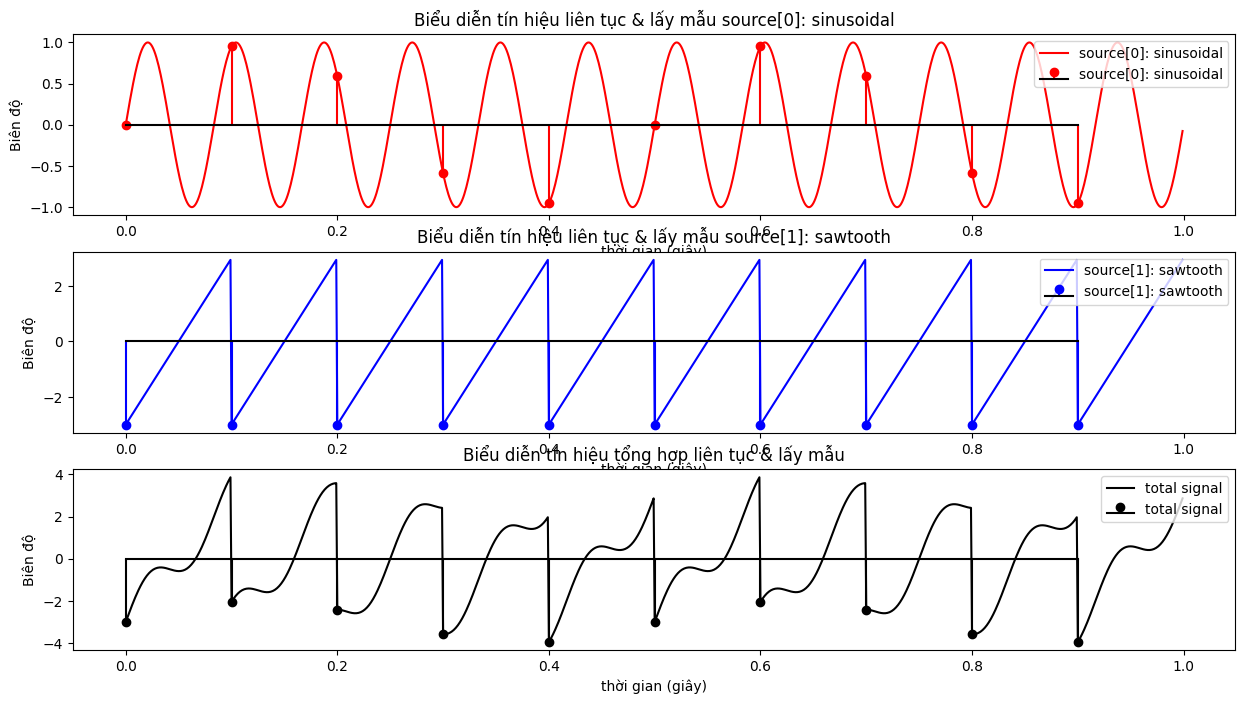

In [97]:
def showcase3(signal_list, duration=1.0, sampling_rate=50.0, superposition=False, components=True):
    
    
    color_list = ['r', 'b', 'g', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan']
    
    # Các mẫu về thời gian
    t_discrete = np.linspace(0, duration, int(duration * sampling_rate), endpoint= False)

    # Vì là mô phỏng nên tín hiệu liên tục được giả lập bởi tín hiệu rời rạc 
    # với tốc độ lấy mẫu gấp nhiều lần so với tín hiệu rời rạc 
    rate_continous = sampling_rate * 100
    t_cont= np.linspace(0, duration, int(duration * rate_continous),endpoint=False)

    fig, ax = plt.subplots(len(signal_list)+1, 1, figsize=(15, 8))

    if len(signal_list)==0:
        return
    
    # tín hiệu tổng hợp: liên tục và rời rạc
    tot_sig_cont = 0
    tot_sig_dist = 0

    for ind, src in enumerate(signal_list):
        sig_type = src['signal_type']
        amp = src['amplitude']
        freq = src['frequency']
        t_sh = src['time_shift']
        
        # Thêm amplitude vào hàm gen_continous_signal
        cont_sig = gen_continous_signal(t_cont, time_shift=t_sh, freq=freq, amplitude=amp, signal_type=sig_type)
        discrete_sig = gen_continous_signal(t_discrete, time_shift=t_sh, freq=freq, amplitude=amp, signal_type=sig_type)
        
        if components: 
            color = color_list[ind % len(color_list)]
            ax[ind].plot(t_cont, cont_sig, color=color, label=f'source[{ind}]: {sig_type}')
            ax[ind].stem(t_discrete, discrete_sig, linefmt=f'{color}-', markerfmt=f'{color}o', 
                         basefmt="k-", label=f'source[{ind}]: {sig_type}')  
            ax[ind].set_title(f'Biểu diễn tín hiệu liên tục & lấy mẫu source[{ind}]: {sig_type}')
            ax[ind].set_xlabel('thời gian (giây)')
            ax[ind].set_ylabel('Biên độ')
            ax[ind].legend(loc='upper right')

        tot_sig_cont += cont_sig
        tot_sig_dist += discrete_sig

    if superposition:
        ax[len(signal_list)].plot(t_cont, tot_sig_cont, color='black', label=f'total signal')
        ax[len(signal_list)].stem(t_discrete, tot_sig_dist, linefmt='k-', markerfmt='ko', 
                                  basefmt="k-", label=f'total signal')
        ax[len(signal_list)].set_title(f'Biểu diễn tín hiệu tổng hợp liên tục & lấy mẫu')
        ax[len(signal_list)].set_xlabel('thời gian (giây)')
        ax[len(signal_list)].set_ylabel('Biên độ')
        ax[len(signal_list)].legend(loc='upper right')


    plt.show()

signal_list = []

source1 = signal_description('sinusoidal', amplitude= 1, freq= 12.0, time_shift= 0)
source2 = signal_description('sawtooth', amplitude= 3, freq= 10, time_shift= 1.9)

signal_list.append(source1)
signal_list.append(source2)

showcase3(signal_list, duration=1.0, sampling_rate=10.0, superposition=True, components=True)

* 
    - Visualization sử dụng ipywidgets
    - Dùng library ipywidgets để trực quan hóa sự thay đổi của tần số lấy mẫu

In [98]:
def update_showcase3(sampling_rate):
    print(sampling_rate)
    signal_list = []

    source1 = signal_description('sinusoidal', amplitude= 1, freq= 12.0, time_shift= 0)
    source2 = signal_description('sawtooth', amplitude= 3, freq= 10.0, time_shift= 0)

    signal_list.append(source1)
    signal_list.append(source2)

    showcase3(signal_list, duration=1.0, sampling_rate=sampling_rate, superposition=True, components=True)

sampling_rate_slider = widgets.IntSlider(value = 24, min = 0 , max = 40, step = 1, description='Sampling Rate')
interact(update_showcase3, sampling_rate = sampling_rate_slider)

interactive(children=(IntSlider(value=24, description='Sampling Rate', max=40), Output()), _dom_classes=('widg…

<function __main__.update_showcase3(sampling_rate)>

##### 5.2.2 Biểu diễn hiện tượng aliasing sau khi lấy mẫu
    a. Lý thuyết về hiện tượng alias
    
Hiện tượng này xảy ra khi $\frac{f_s}{2} < f_{\text{signal}}$
Tín hiệu rời rạc không còn thể hiện tần số của tín hiệu gốc, thay vào đó thể hiện tần số gập alias:

\begin{equation}
\tag{10}
f_{\text{alias}} = \left| f_{\text{signal} - n \times f_s}\right|
\end{equation}
trong đó, $n$ được chọn sao cho $f_{\text{alias}} < \frac{f_s}{2} $ và $\left({\frac{f_s}{2} - f_{\text{alias}}}\right)$ là minimum

In [99]:
def alias_check(fs=2.0, fsig=1.0):
    return (fs /2 < fsig)

In [100]:
class havingNotAlias(Exception):
    pass
def get_alias_freq(fs=1.9, fsig = 1.0):
    n = 0
    falias = fsig
    fnyq = fs / 2 
    while falias >= fnyq:
        n += 1
        falias = np.abs(fsig - n * fs)
    return falias    


In [101]:
def showcase4(signal_list, duration=1.0, sampling_rate=50.0, superposition=False, components=True):
    
    
    color_list = ['r', 'b', 'g', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan']
    
    # Các mẫu về thời gian
    t_discrete = np.linspace(0, duration, int(duration * sampling_rate), endpoint= False)

    # Vì là mô phỏng nên tín hiệu liên tục được giả lập bởi tín hiệu rời rạc 
    # với tốc độ lấy mẫu gấp nhiều lần so với tín hiệu rời rạc 
    rate_continous = sampling_rate * 100
    t_cont= np.linspace(0, duration, int(duration * rate_continous),endpoint=False)

    fig, ax = plt.subplots(len(signal_list)+1, 1, figsize=(15, 8))

    if len(signal_list)==0:
        return
    
    # tín hiệu tổng hợp: liên tục và rời rạc
    tot_sig_cont = 0
    tot_sig_dist = 0

    for ind, src in enumerate(signal_list):
        sig_type = src['signal_type']
        amp = src['amplitude']
        freq = src['frequency']
        t_sh = src['time_shift']
        
        # Thêm amplitude vào hàm gen_continous_signal
        cont_sig = gen_continous_signal(t_cont, time_shift=t_sh, freq=freq, amplitude=amp, signal_type=sig_type)
        discrete_sig = gen_continous_signal(t_discrete, time_shift=t_sh, freq=freq, amplitude=amp, signal_type=sig_type)
        
        if components: 
            color = color_list[ind % len(color_list)]
            ax[ind].plot(t_cont, cont_sig, color=color, label=f'source[{ind}]: {sig_type}')
            ax[ind].stem(t_discrete, discrete_sig, linefmt=f'{color}-', markerfmt=f'{color}o', 
                         basefmt="k-", label=f'source[{ind}]: {sig_type}')  
            
            if alias_check(sampling_rate,freq):
                falias = get_alias_freq(sampling_rate, freq)
                print(f'alisa frequency = {falias}')
                alias_sig = gen_continous_signal(t_cont, time_shift=t_sh, freq=falias, amplitude=amp, signal_type='sinusoidal')
                ax[ind].plot(t_cont, alias_sig, color='purple', ls = ':', label=f'alias of source[{ind}]: {sig_type}')

            ax[ind].set_title(f'Biểu diễn tín hiệu liên tục & lấy mẫu source[{ind}]: {sig_type}')
            ax[ind].set_xlabel('thời gian (giây)')
            ax[ind].set_ylabel('Biên độ')
            ax[ind].legend(loc='upper right')

        tot_sig_cont += cont_sig
        tot_sig_dist += discrete_sig

    if superposition:
        ax[len(signal_list)].plot(t_cont, tot_sig_cont, color='black', label=f'total signal')
        ax[len(signal_list)].stem(t_discrete, tot_sig_dist, linefmt='k-', markerfmt='ko', 
                                  basefmt="k-", label=f'total signal')
        ax[len(signal_list)].set_title(f'Biểu diễn tín hiệu tổng hợp liên tục & lấy mẫu')
        ax[len(signal_list)].set_xlabel('thời gian (giây)')
        ax[len(signal_list)].set_ylabel('Biên độ')
        ax[len(signal_list)].legend(loc='upper right')


    plt.show()

def update_showcase4(sampling_rate):
    # print(sampling_rate)
    signal_list = []

    source1 = signal_description('sinusoidal', amplitude= 1, freq= 10.0, time_shift= 0)
    source2 = signal_description('sinusoidal', amplitude= 3, freq= 10.0, time_shift= 0)

    signal_list.append(source1)
    signal_list.append(source2)

    showcase4(signal_list, duration=2.0, sampling_rate=sampling_rate, superposition=True, components=True)

sampling_rate_slider = widgets.IntSlider(value = 24, min = 0 , max = 40, step = 1, description='Sampling Rate')
interact(update_showcase4, sampling_rate = sampling_rate_slider)

interactive(children=(IntSlider(value=24, description='Sampling Rate', max=40), Output()), _dom_classes=('widg…

<function __main__.update_showcase4(sampling_rate)>

##### 5.3 Biểu diễn sai số khi lượng tử hóa

    1.  Lý thuyết:
        
\begin{equation}
\tag{11}
\text{SQNR} = 6.02 \times n + 1.76
\end{equation}

    2. Hàm showcase5 
        * showcase5 đo giá trị SQNR và so sánh với lý thuyết 
        * được phát triển kế thừa showcase3

In [102]:
def quantization_with_option(signal, levels, min_range=0, max_range=1, normalized_type=None, quantz_type='manual'):
    switcher = {
        'manual': lambda: quantization(signal, levels, min_range, max_range, normalized_type)
    }
    return switcher.get(quantz_type, lambda: quantization(signal, levels, min_range, max_range, normalized_type))()

def measure_energy(signal):
    return np.mean(signal**2)

def sqnr_measure(normalized_signal, quantz_signal):

    noise = normalized_signal - quantz_signal  

    # tranh loi chia cho 0
    sig_noise_ratio = measure_energy(normalized_signal)/(measure_energy(noise) + 1e-6)
    return 10 * np.log10(sig_noise_ratio)

In [103]:
def showcase5(
    signal_list,
    duration=1.0,
    sampling_rate=50.0,
    levels=8,
    superposition=False,
    components=True,
):

    color_list = [
        "r",
        "b",
        "g",
        "orange",
        "purple",
        "brown",
        "pink",
        "gray",
        "olive",
        "cyan",
    ]

    # Các mẫu về thời gian
    t_discrete = np.linspace(0, duration, int(duration * sampling_rate), endpoint=False)

    # Vì là mô phỏng nên tín hiệu liên tục được giả lập bởi tín hiệu rời rạc
    # với tốc độ lấy mẫu gấp nhiều lần so với tín hiệu rời rạc
    rate_continous = sampling_rate * 100
    t_cont = np.linspace(0, duration, int(duration * rate_continous), endpoint=False)

    fig, ax = plt.subplots(3, 1, figsize=(15, 10))

    if len(signal_list) == 0:
        return

    # tín hiệu tổng hợp: liên tục và rời rạc
    tot_sig_cont = 0
    tot_sig_dist = 0

    for ind, src in enumerate(signal_list):
        sig_type = src["signal_type"]
        amp = src["amplitude"]
        freq = src["frequency"]
        t_sh = src["time_shift"]

        # Thêm amplitude vào hàm gen_continous_signal
        cont_sig = gen_continous_signal(
            t_cont, time_shift=t_sh, freq=freq, amplitude=amp, signal_type=sig_type
        )
        discrete_sig = gen_continous_signal(
            t_discrete, time_shift=t_sh, freq=freq, amplitude=amp, signal_type=sig_type
        )

        tot_sig_cont += cont_sig
        tot_sig_dist += discrete_sig

    # Thể hiện tín hiệu tổng hợp: liên tục và rời rạc
    ax[0].plot(t_cont, tot_sig_cont, color="black", label=f"total signal")
    ax[0].stem(
        t_discrete,
        tot_sig_dist,
        linefmt="k-",
        markerfmt="ko",
        basefmt="k-",
        label=f"total signal",
    )

    ax[0].set_title(f"Biểu diễn tín hiệu tổng hợp liên tục & lấy mẫu")
    ax[0].set_xlabel("thời gian (giây)")
    ax[0].set_ylabel("Biên độ")
    ax[0].legend(loc="upper right")

    quantz_sig = quantization_with_option(
        tot_sig_dist,
        levels=4,
        min_range=0,
        max_range=1,
        normalized_type="min_max",
        quantz_type="manual",
    )
    norm_sig = normalizing_signal(tot_sig_dist, normalized_type="min_max")
    norm_tot_cont_sig = normalizing_signal(tot_sig_cont, normalized_type="min_max")

    # Thể hiện tín hiệu tổng hợp sau quantized
    ax[1].plot(t_cont, tot_sig_cont, color="black", label=f"total signal")
    ax[1].stem(
        t_discrete,
        norm_sig,
        linefmt="k-",
        markerfmt="ko",
        basefmt="k-",
        label=f"total signal",
    )
    ax[1].stem(
        t_discrete,
        quantz_sig,
        linefmt="r:",
        markerfmt="rx",
        basefmt="r:",
        label=f"quantized",
    )

    maxbit = 13
    sqnr_arr_emp = []
    sqnr_arr_theo = []
    for numbit in np.arange(1, maxbit):
        levels = 2**numbit
        sig_list = quantization_with_option(
            tot_sig_dist,
            levels=levels,
            min_range=0,
            max_range=1,
            normalized_type=None,
            quantz_type="manual",
        )
        quantz_sig = sig_list[0]
        sqnr_emp = sqnr_measure(tot_sig_dist, quantz_sig)
        sqnr_arr_emp.append(sqnr_emp)
        sqnr_theo = 6.02 * numbit + 1.76
        sqnr_arr_theo.append(sqnr_theo)

    sqnr_arr_emp = np.array(sqnr_arr_emp)
    sqnr_arr_theo = np.array(sqnr_arr_theo)

    ax[2].plot(
        np.arange(1, maxbit),
        sqnr_arr_theo,
        color="blue",
        label="SQNR theoretical (6.02n + 1.76)",
    )

    ax[2].stem(
        np.arange(1, maxbit),
        sqnr_arr_emp,
        linefmt="b-",
        markerfmt="bo",
        basefmt="k-",
        label="SQNR empirical",
    )

    ax[2].set_title("Biểu diễn SQNR")
    ax[2].set_xlabel("number of bits")
    ax[2].set_ylabel("SQNR (dB)")
    ax[2].legend(loc="upper right")

    plt.show()


def update_showcase5(sampling_rate):
    print(sampling_rate)
    signal_list = []

    source1 = signal_description("sinusoidal", amplitude=1, freq=12.0, time_shift=0)
    source2 = signal_description("sawthoot", amplitude=0.5, freq=100.0, time_shift=0)

    signal_list.append(source1)

    showcase5(
        signal_list,
        duration=1.0,
        sampling_rate=sampling_rate,
        superposition=True,
        components=True,
    )


sampling_rate_slider = widgets.IntSlider(
    value=24, min=0, max=200, step=1, description="Sampling Rate"
)
interact(update_showcase5, sampling_rate=sampling_rate_slider)

interactive(children=(IntSlider(value=24, description='Sampling Rate', max=200), Output()), _dom_classes=('wid…

<function __main__.update_showcase5(sampling_rate)>

In [104]:
print(min_max_norm([0, 0, 0, 0, -1, 1]))

[0.5 0.5 0.5 0.5 0.  1. ]
